# Building Command-Line Tools

A **command-line interface (CLI)** lets people and other programs run your code with options: `python -m mytool report --since 2025-01-01 --format json`. Data and ML teams build CLIs for training jobs, data exports and maintenance tasks, because a CLI is easy to schedule, script and run in a container.

**After this lesson you can:**

1. Build a CLI with the standard `argparse` module.
2. Build a CLI with **Typer**, which uses type hints.
3. Use exit codes, standard input/output and standard error correctly.
4. Install a CLI as a command with `[project.scripts]`.

## 1. CLI Conventions

| Convention | Meaning |
| :--- | :--- |
| positional argument | required input: `csvstats data.csv` |
| option / flag | optional: `--column price`, `-v` |
| `--help` | prints usage; every CLI must support it |
| **exit code** | `0` = success, non-zero = error; scripts and CI check it |
| **stdout** | the result (so it can be piped to another program) |
| **stderr** | messages and errors (not mixed into the result) |

In [1]:
import json
import random
import subprocess
import sys
import tempfile
import textwrap
from pathlib import Path

work = Path(tempfile.mkdtemp())
random.seed(5)
data = work / "orders.csv"
data.write_text("order_id,city,price\n" + "\n".join(
    f"{i},{random.choice(['Ankara', 'İzmir', 'Bursa'])},{random.lognormvariate(4, 0.6):.2f}" for i in range(1, 501)) + "\n",
    encoding="utf-8")
print(data.read_text(encoding="utf-8").splitlines()[:4])

['order_id,city,price', '1,Bursa,36.88', '2,Bursa,29.23', '3,Bursa,20.02']


## 2. A CLI with `argparse`

`argparse` is in the standard library. It parses the arguments, converts types, prints `--help` and reports errors.

In [2]:
(work / "csvstats.py").write_text(textwrap.dedent("""
    import argparse
    import csv
    import json
    import statistics
    import sys

    def main(argv=None) -> int:
        parser = argparse.ArgumentParser(prog="csvstats", description="Summary statistics for one CSV column.")
        parser.add_argument("path", help="CSV file to read")
        parser.add_argument("--column", "-c", required=True, help="numeric column name")
        parser.add_argument("--group-by", "-g", help="optional column to group by")
        parser.add_argument("--format", choices=["text", "json"], default="text")
        args = parser.parse_args(argv)

        with open(args.path, newline="", encoding="utf-8") as f:
            rows = list(csv.DictReader(f))
        if not rows or args.column not in rows[0]:
            print(f"error: column {args.column!r} not found", file=sys.stderr)
            return 2

        groups = {}
        for r in rows:
            key = r[args.group_by] if args.group_by else "all"
            groups.setdefault(key, []).append(float(r[args.column]))
        result = {k: {"n": len(v), "mean": round(statistics.mean(v), 2), "median": round(statistics.median(v), 2),
                      "max": max(v)} for k, v in sorted(groups.items())}

        if args.format == "json":
            print(json.dumps(result, ensure_ascii=False))
        else:
            for k, s in result.items():
                print(f"{k:<8} n={s['n']:<4} mean={s['mean']:<8} median={s['median']:<8} max={s['max']}")
        return 0

    if __name__ == "__main__":
        sys.exit(main())
"""))

def run(*args):
    r = subprocess.run([sys.executable, *args], cwd=work, capture_output=True, text=True)
    print(f"$ python {' '.join(args)}\n{r.stdout}{r.stderr}(exit code {r.returncode})\n")
    return r

_ = run("csvstats.py", "--help")
_ = run("csvstats.py", "orders.csv", "-c", "price", "-g", "city")
_ = run("csvstats.py", "orders.csv", "-c", "amount")

$ python csvstats.py --help
usage: csvstats [-h] --column COLUMN [--group-by GROUP_BY]
                [--format {text,json}]
                path

Summary statistics for one CSV column.

positional arguments:
  path                  CSV file to read

options:
  -h, --help            show this help message and exit
  --column COLUMN, -c COLUMN
                        numeric column name
  --group-by GROUP_BY, -g GROUP_BY
                        optional column to group by
  --format {text,json}
(exit code 0)

$ python csvstats.py orders.csv -c price -g city
Ankara   n=170  mean=67.25    median=58.58    max=356.2
Bursa    n=166  mean=58.02    median=51.45    max=202.36
İzmir    n=164  mean=63.07    median=52.95    max=240.82
(exit code 0)



$ python csvstats.py orders.csv -c amount
error: column 'amount' not found
(exit code 2)



The wrong column name produced a message on **stderr** and exit code 2. A shell script or a CI job can check the exit code and stop.

## 3. A CLI with Typer

**Typer** builds a CLI from the **type hints** of a function. It supports sub-commands, so one tool can have several actions (`git commit`, `git push`).

In [3]:
(work / "modeltool.py").write_text(textwrap.dedent("""
    import json
    from enum import Enum
    from pathlib import Path

    import typer

    app = typer.Typer(help="Train and inspect tiny models.")

    class Kind(str, Enum):
        mean = "mean"
        median = "median"

    @app.command()
    def train(data: Path, column: str = "price", kind: Kind = Kind.mean, out: Path = Path("model.json")):
        \"\"\"Fit a constant model on one column and save it.\"\"\"
        import csv, statistics
        values = [float(r[column]) for r in csv.DictReader(data.open(encoding="utf-8"))]
        value = statistics.mean(values) if kind is Kind.mean else statistics.median(values)
        out.write_text(json.dumps({"kind": kind.value, "value": round(value, 2), "n": len(values)}))
        typer.echo(f"saved {out} ({kind.value} = {value:.2f}, n = {len(values)})")

    @app.command()
    def show(model: Path = Path("model.json")):
        \"\"\"Print a saved model.\"\"\"
        if not model.exists():
            typer.echo(f"no model at {model}", err=True)
            raise typer.Exit(code=1)
        typer.echo(model.read_text())

    if __name__ == "__main__":
        app()
"""))
_ = run("modeltool.py", "--help")
_ = run("modeltool.py", "train", "orders.csv", "--kind", "median")
_ = run("modeltool.py", "show")

$ python modeltool.py --help
                                                                                
 Usage: modeltool.py [OPTIONS] COMMAND [ARGS]...                                
                                                                                
 Train and inspect tiny models.                                                 
                                                                                
╭─ Options ────────────────────────────────────────────────────────────────────╮
│ --install-completion        <bool>  Install completion for the current       │
│                                     shell.                                   │
│ --show-completion           <bool>  Show completion for the current shell,   │
│                                     to copy it or customize the              │
│                                     installation.                            │
│ --help                      <bool>  Show this message and exit.              │

$ python modeltool.py train orders.csv --kind median
saved model.json (median = 53.30, n = 500)
(exit code 0)



$ python modeltool.py show
{"kind": "median", "value": 53.3, "n": 500}
(exit code 0)



## 4. Use the CLI Output in Another Program

Because the CLI writes machine-readable JSON to stdout, other programs can use it directly. The notebook calls the CLI and plots its result.

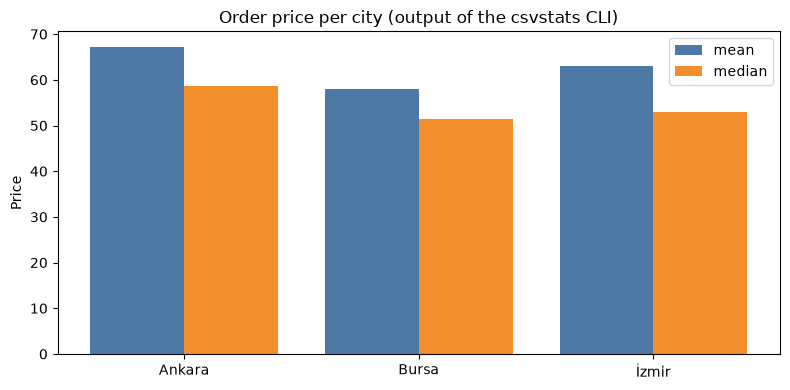

In [4]:
import matplotlib.pyplot as plt

r = subprocess.run([sys.executable, "csvstats.py", "orders.csv", "-c", "price", "-g", "city", "--format", "json"],
                   cwd=work, capture_output=True, text=True, check=True)
stats = json.loads(r.stdout)

fig, ax = plt.subplots(figsize=(8, 4))
cities = list(stats)
ax.bar([i - 0.2 for i in range(len(cities))], [stats[c]["mean"] for c in cities], width=0.4, color="#4E79A7", label="mean")
ax.bar([i + 0.2 for i in range(len(cities))], [stats[c]["median"] for c in cities], width=0.4, color="#F28E2B", label="median")
ax.set_xticks(range(len(cities)), cities)
ax.set(title="Order price per city (output of the csvstats CLI)", ylabel="Price")
ax.legend()
plt.tight_layout()
plt.show()

The mean is above the median in every city: the synthetic prices come from a log-normal (right-skewed) distribution (M06).

## 5. Install a CLI as a Command

In a package, declare the command in `pyproject.toml`. After installation, the command is on the `PATH`:

```toml
[project.scripts]
csvstats = "mypackage.cli:main"        # command = module:function
```

```bash
uv tool install .        # install the command globally, in its own environment
uvx ruff check .         # run a published CLI without installing it
```

*Insight: Design a CLI for two users: humans (clear `--help`, readable text) and programs (JSON on stdout, errors on stderr, meaningful exit codes). Then the same tool works in a terminal, a cron job, a CI pipeline and a container.*

## Real-World Use Case or Analogy

A CLI is like the **control panel of a machine** in a factory: labelled buttons and dials (options), a manual on the side (`--help`), and a green or red light when the job ends (exit code). An operator can run it by hand, and a production schedule can run it automatically.

Most tools in this course are CLIs: `uv`, `ruff`, `pytest`, `git`, `docker`, `kubectl`, `dbt`, `mlflow`. Training scripts in ML teams are CLIs too (`python train.py --lr 3e-4 --epochs 10`), so that an orchestrator such as Airflow or Kubeflow can run them with different parameters (M11, M34).